# Imports

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

# Point Processes

We are dealing with two csv files.Important to note that the dataset has been anonymized .

`features.csv`: Contains patient features. Does not provide information about what each of this features mean. Labeled as F0,F1,..., F7

`timelines.csv`: Patient event times. Time is encoded in months and as a relative difference with respect to the previous event.

In [29]:
features = pd.read_csv("features.csv", sep=";")
timelines = pd.read_csv("timelines.csv", sep=";")

In [30]:
features

,ID,F0,F1,F2,F3,F4,F5,F6,F7
0,GIMO0741213000,0,0.260539,1,0,0,0,0,0
1,MAMA1770428016,1,0.343443,0,1,0,0,0,0
2,NHC14160717,1,0.740823,0,1,0,0,0,0
3,ARAR1670527002,1,0.459585,0,0,1,1,0,0
4,14665507,1,0.437052,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...
1107,BETA1850704002,1,0.319240,0,0,1,0,1,1
1108,14031598,1,0.477108,0,1,0,0,0,1
1109,LUCA1741008007,1,0.432726,0,1,0,0,1,1
1110,PALO1760413000,1,0.418051,0,1,0,0,0,1


In [31]:
timelines

,ID,time_1,time_2,time_3,time_4,time_5,time_6,time_7,time_8,time_9,time_10,time_11
0,GIMO0741213000,14.113621,1.300479,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,MAMA1770428016,8.813142,0.002738,0.884326,0.087611,0.169747,0.019165,0.024641,0.804928,0.032854,0.156057,0.073923
2,NHC14160717,7.745380,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,ARAR1670527002,7.477070,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,14665507,6.965092,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
1107,BETA1850704002,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1108,14031598,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1109,LUCA1741008007,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1110,PALO1760413000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## Preprocessing

Data has been anonymized, however, we will analyze it briefly to check for NA values as well as to see the data we are dealing with.

For simplicity, we will merge both datasets into 1.

We see that 7 of our variables are binary, we will plot them 

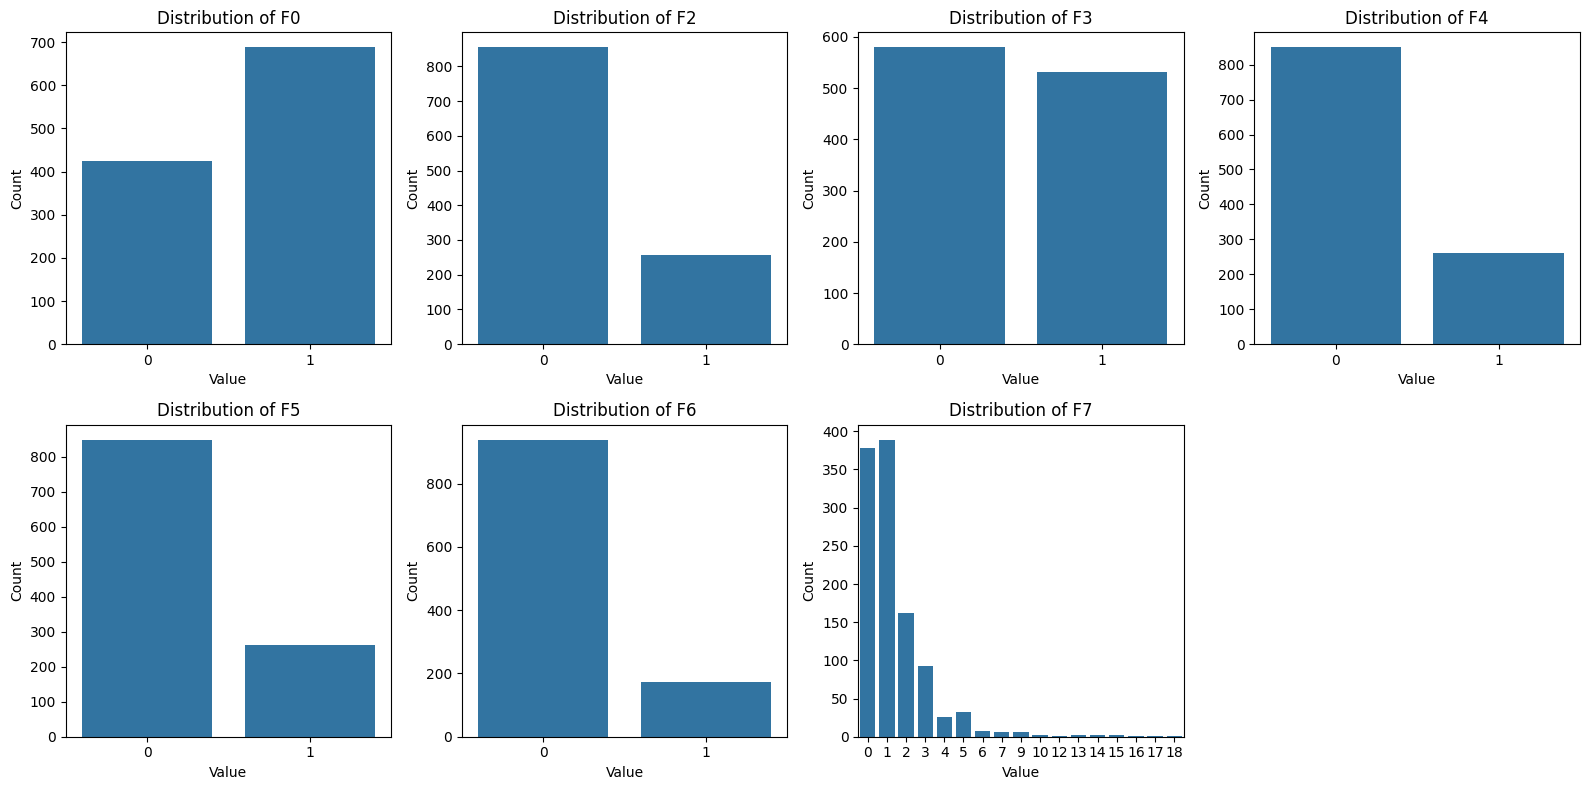

In [32]:
cols = ['F0', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=features, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')

# Unused plots
axes[-1].remove() 

plt.tight_layout()
plt.show()

Variables such as F2, F4, F5 or F6 show some imbalance between each of the classes. F3 is more or less equilibrated.

This is very important for scaling, as with StandardScaler, a value of 1 in the column F6 will have a much larger standardized value than for example a 1 in F3, inflating a value just because of it being more frequent.

Additionally, F7 has more of its counts for values less or equal to 3. Remaining elements have very low frquency which also affects our analysis. Therefore, we will log covert this variable so the gap between 0-3 and the remaining values is not as elevated. Afterwards we will apply MinMax scaler.

Additionally, as most of our variables are binary, it is possible K-Means with Euclidean distance is affected by 0s and 1s combinations, rather than variations in variables such as F1 or F7. We will use K-Means as a starting point but we might have to try a different method

<Axes: xlabel='F7', ylabel='F1'>

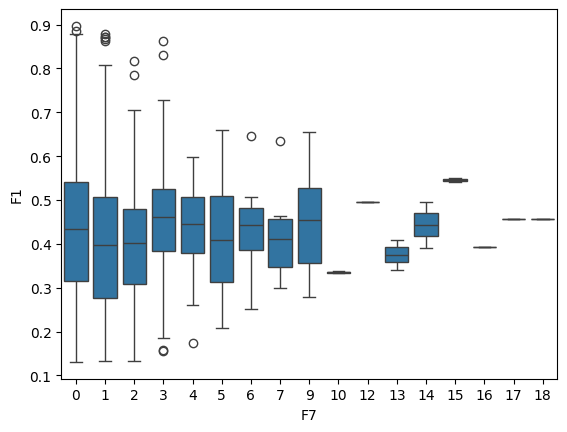

In [33]:
sns.boxplot(features, x = features["F7"], y = features["F1"])

If an event has not happened at time 0 it is a value of 0.0. And the following timestamps will have a value of 0. Therefore, we have to remove patients which do not follow this structure.


For Hawkes process, we have to define the events with respect to a common starting point rather than the previous timestamp

In [34]:
for i in range(1, 10):
    invalid = (timelines[f'time_{i}'] == 0) & (timelines[f'time_{i+1}'] > 0)
    print(f"time_{i} violations:", invalid.sum())

time_1 violations: 1
time_2 violations: 0
time_3 violations: 0
time_4 violations: 0
time_5 violations: 0
time_6 violations: 0
time_7 violations: 0
time_8 violations: 0
time_9 violations: 0


In [35]:
# We have a single patient, whose value is larger than 0 at time 2 when at time one we had a value of 0
timelines[(timelines["time_1"] == 0) & (timelines["time_2"]>0.0)]

,ID,time_1,time_2,time_3,time_4,time_5,time_6,time_7,time_8,time_9,time_10,time_11
138,AYZA1840525007,0.0,0.087611,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [36]:
# Removing the patient.
bad_id = "AYZA1840525007"
features  = features[features["ID"] != bad_id].reset_index(drop=True)
timelines = timelines[timelines["ID"] != bad_id].reset_index(drop=True)

# Makes sure both tables have the same index
timelines = timelines.set_index("ID").loc[features["ID"]].reset_index()

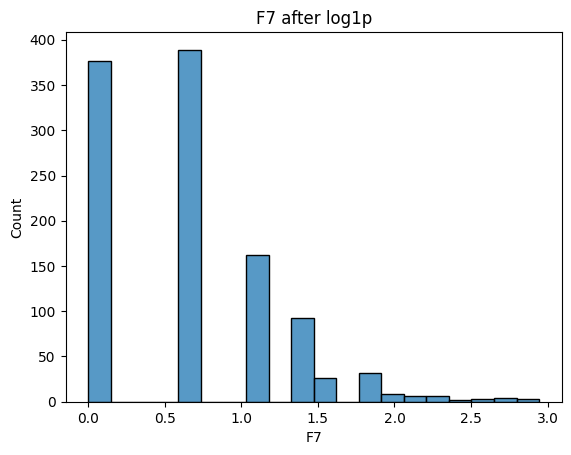

In [41]:
from sklearn.preprocessing import MinMaxScaler

# Sacling, converting the last feature and keeping the ID as index as it is not used by the clusering
X = features.copy()

# Converting F7 as explained above
X = features.drop(columns="ID").copy()
X["F7"] = np.log1p(X["F7"])
data_norm = pd.DataFrame(MinMaxScaler().fit_transform(X),
                         columns=X.columns, index=features["ID"])

sns.histplot(X["F7"], bins=20)
plt.title("F7 after log1p")
plt.show()


In [38]:
X.head()

,F0,F1,F2,F3,F4,F5,F6,F7
0,0,0.260539,1,0,0,0,0,0.0
1,1,0.343443,0,1,0,0,0,0.0
2,1,0.740823,0,1,0,0,0,0.0
3,1,0.459585,0,0,1,1,0,0.0
4,1,0.437052,0,0,1,0,0,0.0


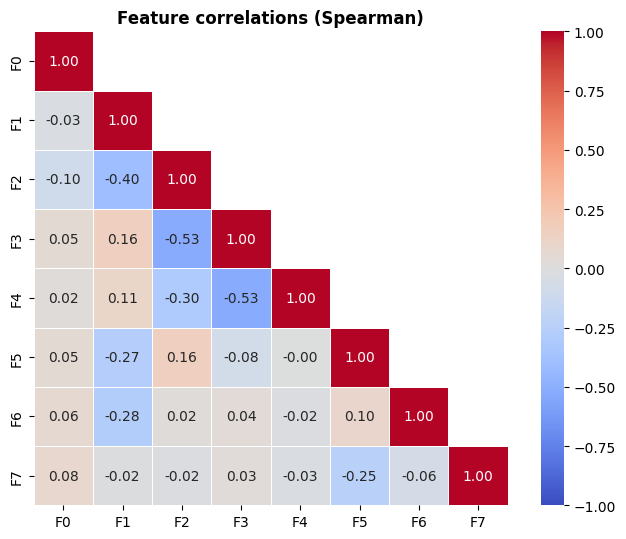

In [42]:
# Correlation Plot
corr = X.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Feature correlations (Spearman)", fontweight="bold")
plt.tight_layout()
plt.show()

## Clustering

Clustering must only be applied on the features. Timelines will be used on the posterior Hawkes process.

`Calinski-Harabasz`: Ratio of the sum of inter-cluster dispersion and the sum of intra-cluster dispersion for all clusters. The higher the better

`Davies-Bouldin`: Average similarity of each cluster with a cluster more similar to it. The lower the average similarity is, the better. Similarity is defined as the ratio of within-cluster scatter to between-cluster distances

`Silhouette Score`: How well each data point fits within its assignated cluster and how well separated it is from other clusters. Returns a value between 1 and -1. 0 indicates overlap, negative values means a point has been incorrectly assigned.

`Elbow Method`: We compute the Within-Cluster Sum of Squares (WCSS) for various values of k. We will obtain a plot in a decreasing manner, we will select the cluster located at the elbow.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

In [18]:
K = list(range(2,9))

wcss, ch_scores, db_scores, sh_scores = [], [], [], []
for k in K:
    kmeans = KMeans(n_clusters=k, random_state= 42, init="k-means++").fit(data_norm)
    wcss.append(kmeans.inertia_)
    labels = kmeans.labels_
    ch_scores.append(calinski_harabasz_score(data_norm, labels))
    db_scores.append(davies_bouldin_score(data_norm, labels))
    sh_scores.append(silhouette_score(data_norm, labels))

metrics_df = pd.DataFrame({
    "K": K,
    "WCSS": wcss,
    "Silhouette Score": sh_scores,
    "Calinski-Harabasz": ch_scores,
    "Davies-Bouldin": db_scores
})

print(metrics_df.to_string(index=False))

 K       WCSS  Silhouette Score  Calinski-Harabasz  Davies-Bouldin
 2 986.695784          0.303305         440.797574        1.515919
 3 737.356568          0.385496         482.167309        1.226418
 4 660.280317          0.353372         401.757537        1.210863
 5 582.974898          0.349222         377.664903        1.416548
 6 520.114941          0.379900         365.074762        1.123022
 7 454.140077          0.402893         374.865252        1.155299
 8 388.011142          0.432842         402.613608        0.994547


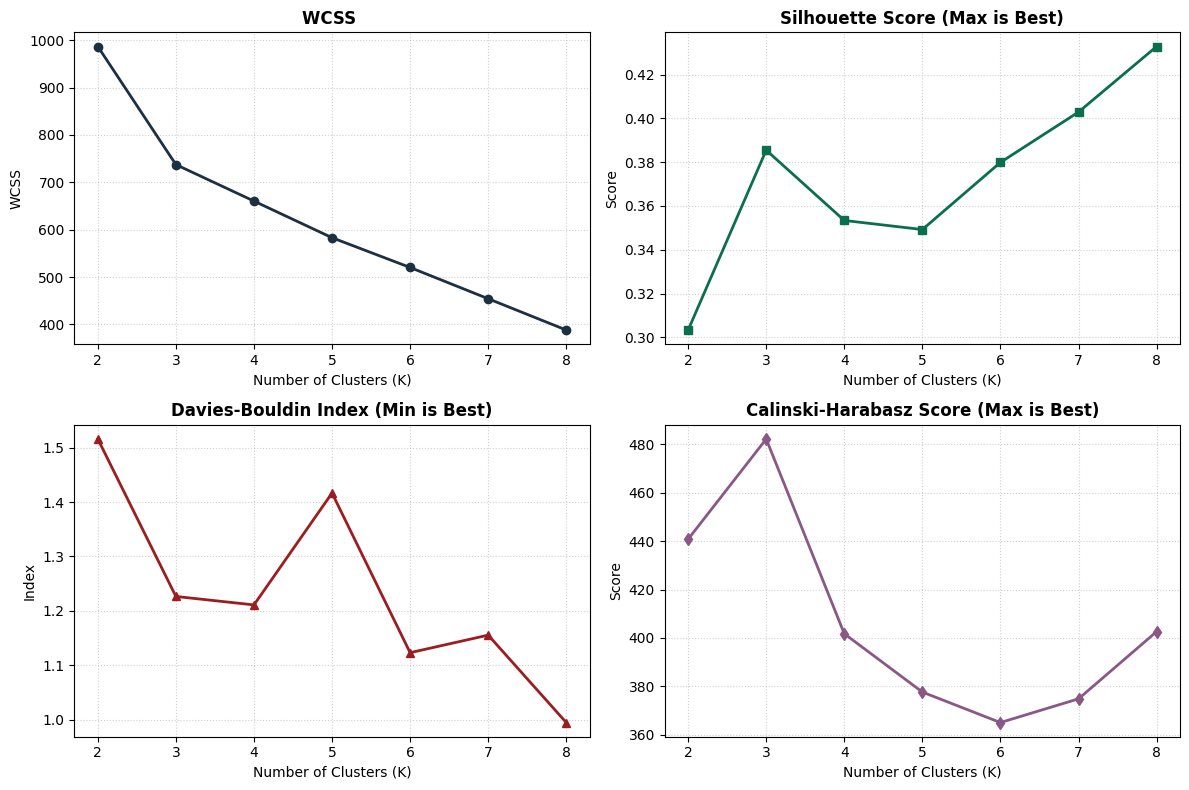

In [19]:

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

#  WCSS /Inertia (Elbow)
axs[0, 0].plot(K, wcss, marker="o", color="#1C3041", linewidth=2)
axs[0, 0].set_title("WCSS ", fontweight="bold")
axs[0, 0].set_xlabel("Number of Clusters (K)")
axs[0, 0].set_ylabel("WCSS")
axs[0, 0].grid(True, linestyle=":", alpha=0.6)

# Silhouette Score (Higher = Better)
axs[0, 1].plot(K, sh_scores, marker="s", color="#0B6E4F", linewidth=2)
axs[0, 1].set_title("Silhouette Score (Max is Best)", fontweight="bold")
axs[0, 1].set_xlabel("Number of Clusters (K)")
axs[0, 1].set_ylabel("Score")
axs[0, 1].grid(True, linestyle=":", alpha=0.6)

#  Davies-Bouldin Index (Lower = Better)
axs[1, 0].plot(K, db_scores, marker="^", color="#9B1D20", linewidth=2)
axs[1, 0].set_title("Davies-Bouldin Index (Min is Best)", fontweight="bold")
axs[1, 0].set_xlabel("Number of Clusters (K)")
axs[1, 0].set_ylabel("Index")
axs[1, 0].grid(True, linestyle=":", alpha=0.6)

# Calinski-Harabasz Score (Higher = Better)
axs[1, 1].plot(K, ch_scores, marker="d", color="#895884", linewidth=2)
axs[1, 1].set_title("Calinski-Harabasz Score (Max is Best)", fontweight="bold")
axs[1, 1].set_xlabel("Number of Clusters (K)")
axs[1, 1].set_ylabel("Score")
axs[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


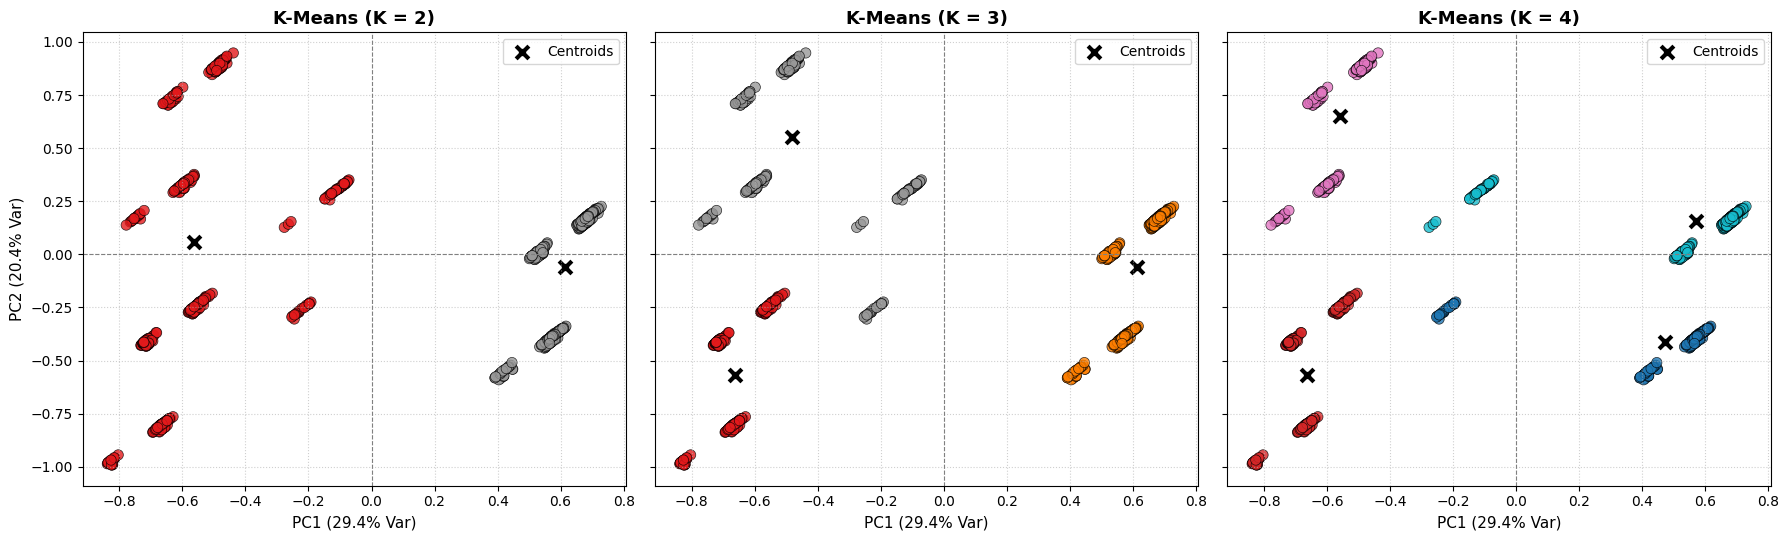

In [20]:
pca_2d = PCA(n_components=2)
x_pca_2d = pca_2d.fit_transform(data_norm)
var_exp = pca_2d.explained_variance_ratio_ * 100

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
k_values = [2, 3, 4]

for i, k in enumerate(k_values):
    ax = axs[i]
    kmeans = KMeans(n_clusters=k, random_state=42, init="k-means++", n_init=10)
    labels = kmeans.fit_predict(data_norm)

    # Project cluster centroids to the 2D PCA space
    centers_2d = pca_2d.transform(kmeans.cluster_centers_)

    scatter = ax.scatter(
        x_pca_2d[:, 0],
        x_pca_2d[:, 1],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=55,
        alpha=0.8,
        edgecolors="k",
        linewidths=0.5,
    )

    # Plot projected centroids
    ax.scatter(
        centers_2d[:, 0],
        centers_2d[:, 1],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Centroids",
    )

    ax.set_title(f"K-Means (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=11)
    if i == 0:
        ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=11)

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

K-Means results are complicated to interpret in our current dataset. This is because most features are binary flags, therefore, centroids may be fractional values which do not correspond to an actual patient profiel. Moreover, K-Means assumes spherical clusters. Therefore, we will move to hierarchical clustering on a precomputed distance matrix.

All features are scaled to [0,1] with MinMax, Manhattan distance averaged over features is like a Gower distance, therefore, each binary variable contributes 0 or 1 to the dissimilarity, F1 nad F7 contribute their scaled difference.

Metrics such as Davies-Boulding or Calinski-Harabasz rely on Euclidean distance, which is not the case here. Therefore, we use the silhouette score to evaluate our method

In [46]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances

# Precomputed distance matrix
D = pairwise_distances(data_norm, metric="manhattan") / data_norm.shape[1]

rows = []
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, metric="precomputed",
                                  linkage="average").fit_predict(D)
    rows.append({"K": k, "silhouette": silhouette_score(D, lab, metric="precomputed"),
                 "sizes": np.bincount(lab).tolist()})
pd.DataFrame(rows)

,K,silhouette,sizes
0,2,0.382413,"[853, 258]"
1,3,0.522169,"[588, 258, 265]"
2,4,0.454689,"[265, 258, 481, 107]"
3,5,0.434402,"[258, 228, 481, 107, 37]"
4,6,0.436052,"[481, 228, 138, 107, 37, 120]"
5,7,0.449745,"[228, 37, 138, 107, 425, 120, 56]"
6,8,0.471692,"[37, 425, 138, 107, 54, 120, 56, 174]"


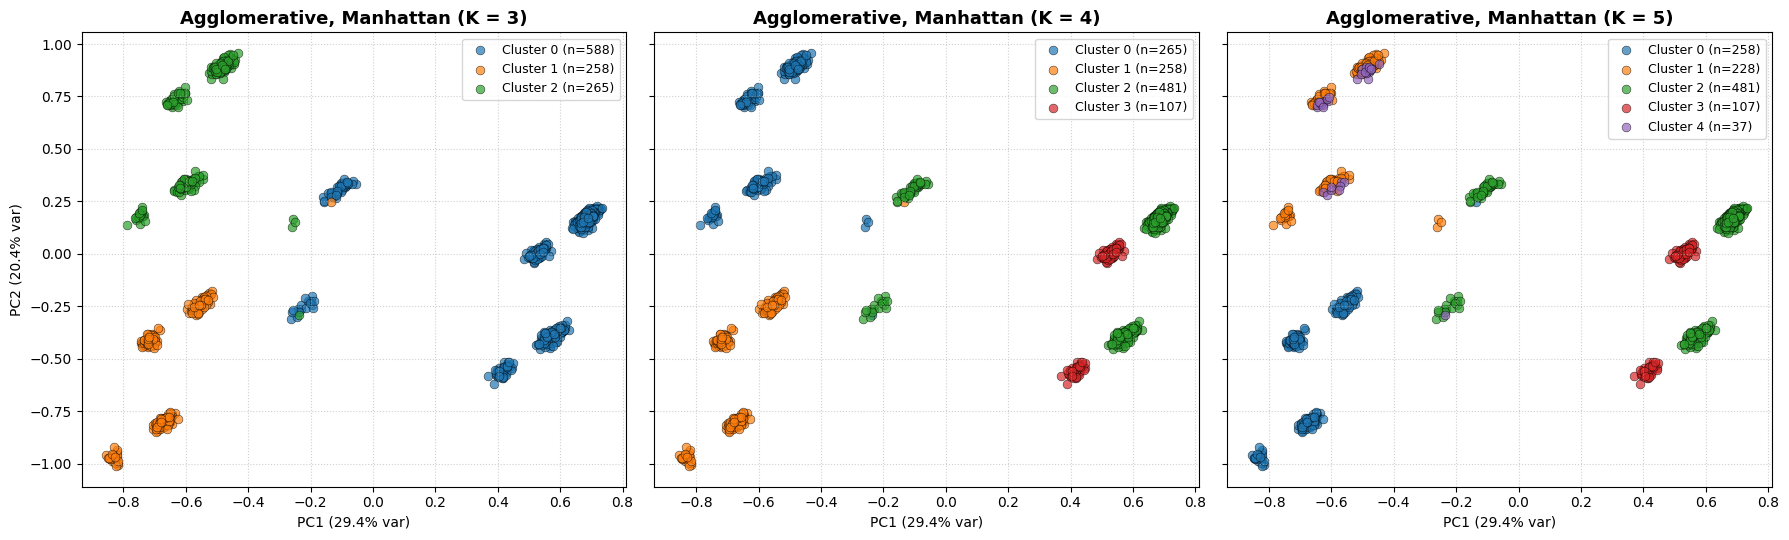

In [47]:

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(data_norm)
var = pca.explained_variance_ratio_ * 100

# Binary data makes many points identical in PCA space, we add small noise
rng = np.random.default_rng(42)
Zj = Z + rng.normal(scale=0.01, size=Z.shape)

cmap = plt.get_cmap("tab10")
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)

for ax, k in zip(axs, [3, 4, 5]):
    lab = AgglomerativeClustering(n_clusters=k, metric="precomputed",
                                  linkage="average").fit_predict(D)
    for c in range(k):
        m = lab == c
        ax.scatter(Zj[m, 0], Zj[m, 1], s=40, alpha=0.7, color=cmap(c),
                   edgecolors="k", linewidths=0.4, label=f"Cluster {c} (n={m.sum()})")
    ax.set_title(f"Agglomerative, Manhattan (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var[0]:.1f}% var)")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="best", fontsize=9)

axs[0].set_ylabel(f"PC2 ({var[1]:.1f}% var)")
plt.tight_layout()
plt.show()

After careful analysis, K=3 seems like the best choice. It represents clearly the largest silhouette score and with a reasonable margin with K=4. We can see that each of the groups are representative, with at least around 250 patients per group. 

Moreover, the PCA plot groups data clearly, we can see that for example for K=5 we can observe some overlap. However, this is not too conclusive as we have to keep in mind that our current PCA plot contains around 50% of the data variance, which is not all of it. There is a clear distinction which is due to the 0 1 values. About 15 separate data blobs.

We have seen that variables are not too correlated and as they cannot be correlated, this seems like a reasonable approach to this problem.